# Store Sales Forecasting — Time Series Machine Learning

**Goal:** predict aggregate daily sales across all stores and product families for the next 16 days using Kaggle Store Sales data.
**Evaluation design:** a 16-day chronological holdout immediately preceding the Kaggle test period. All lagged and rolling sales features look back at least 16 days, so validation and future prediction do not require actual sales inside the forecast horizon. `onpromotion` is known in both train and test.

**Data provenance:** Kaggle *Store Sales — Time Series Forecasting* (Corporación Favorita).

## 1. Imports and load data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA=Path('data')
train=pd.read_csv(DATA/'train.csv',usecols=['date','sales','onpromotion'],parse_dates=['date'])
test=pd.read_csv(DATA/'test.csv',usecols=['date','onpromotion'],parse_dates=['date'])
print('Training rows:',len(train),'Test rows:',len(test))
train.head()

Training rows: 3000888 Test rows: 28512


,date,sales,onpromotion
0,2013-01-01,0.0,0
1,2013-01-01,0.0,0
2,2013-01-01,0.0,0
3,2013-01-01,0.0,0
4,2013-01-01,0.0,0


## 2. Aggregate the panel dataset into one daily series

In [2]:
daily=(train.groupby('date',as_index=False)
       .agg(sales=('sales','sum'),onpromotion=('onpromotion','sum'))
       .set_index('date').asfreq('D'))
daily['sales']=daily['sales'].fillna(0)
daily['onpromotion']=daily['onpromotion'].fillna(0)
test_daily=(test.groupby('date',as_index=False)
            .agg(onpromotion=('onpromotion','sum'))
            .set_index('date').asfreq('D'))
print('History:',daily.index.min().date(),'to',daily.index.max().date())
print('Future:',test_daily.index.min().date(),'to',test_daily.index.max().date())
daily.head()

History: 2013-01-01 to 2017-08-15
Future: 2017-08-16 to 2017-08-31


,sales,onpromotion
date,,
2013-01-01,2511.618999,0.0
2013-01-02,496092.417944,0.0
2013-01-03,361461.231124,0.0
2013-01-04,354459.677093,0.0
2013-01-05,477350.121229,0.0


The original dataset contains separate rows per **date × store × product family**. Summing produces a single national-level daily total, suitable for a clear forecasting demonstration. Store metadata, oil prices, and holiday records are included in the archive but not used as model features: this baseline keeps the feature availability and forecast horizon unambiguous. Missing dates introduced by daily reindexing are treated as zero; check the original calendar before using this approach in production.

## 3. Explore trend and weekly patterns

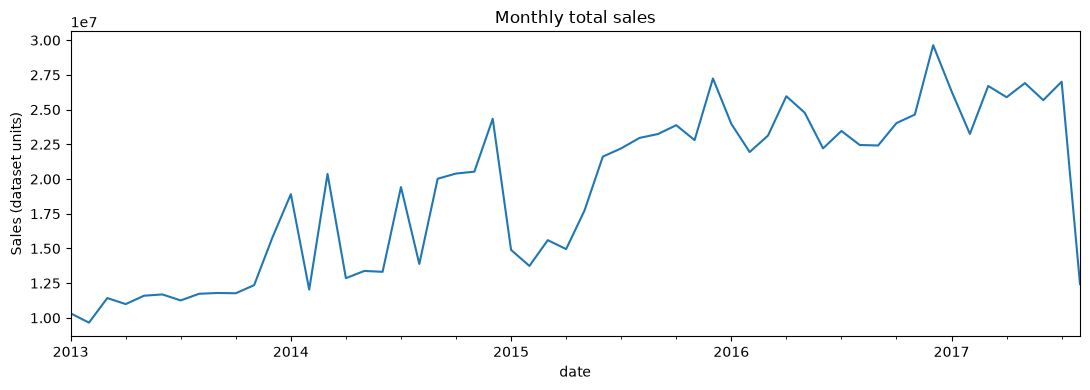

In [3]:
fig,ax=plt.subplots(figsize=(11,4))
daily['sales'].resample('MS').sum().plot(ax=ax)
ax.set_title('Monthly total sales');ax.set_ylabel('Sales (dataset units)');plt.tight_layout();plt.show()

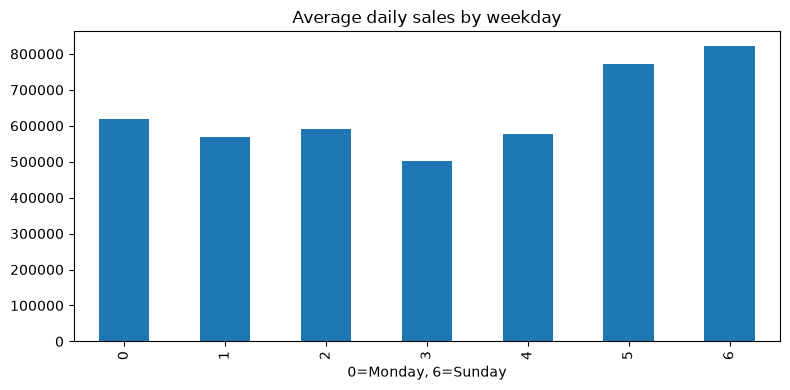

In [4]:
fig,ax=plt.subplots(figsize=(8,4))
daily.groupby(daily.index.dayofweek)['sales'].mean().plot(kind='bar',ax=ax)
ax.set_title('Average daily sales by weekday');ax.set_xlabel('0=Monday, 6=Sunday');plt.tight_layout();plt.show()

## 4. Horizon-safe feature engineering

In [5]:
HORIZON=16
LAGS=[16,21,28,35,56]

def make_features(sales,promo):
    out=pd.DataFrame(index=sales.index)
    out['dayofweek']=out.index.dayofweek
    out['dayofmonth']=out.index.day
    out['month']=out.index.month
    out['dayofyear']=out.index.dayofyear
    out['time_index']=(out.index-out.index.min()).days
    out['onpromotion']=promo
    for lag in LAGS:
        out[f'lag_{lag}']=sales.shift(lag)
    for window in [7,14,28]:
        out[f'rolling_mean_{window}_shift16']=sales.shift(HORIZON).rolling(window).mean()
    return out

full_index=daily.index.append(test_daily.index)
all_sales=daily['sales'].reindex(full_index)
all_promo=pd.concat([daily['onpromotion'],test_daily['onpromotion']]).reindex(full_index)
Xall=make_features(all_sales,all_promo)
X=Xall.loc[daily.index]
y=daily['sales']
X.head()

,dayofweek,dayofmonth,month,dayofyear,time_index,onpromotion,lag_16,lag_21,lag_28,lag_35,lag_56,rolling_mean_7_shift16,rolling_mean_14_shift16,rolling_mean_28_shift16
date,,,,,,,,,,,,,,
2013-01-01,1,1,1,1,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2013-01-02,2,2,1,2,1,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2013-01-03,3,3,1,3,2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2013-01-04,4,4,1,4,3,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2013-01-05,5,5,1,5,4,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Why shift by 16?** For any prediction day in a 16-day batch, `lag_16` and the shifted rolling windows only reference sales before the batch begins. Thus the model never needs to know actual sales from earlier days within that same prediction horizon. The future `onpromotion` feature is supplied by Kaggle test data; it is not inferred from actual future sales.

## 5. Chronological validation and baseline

In [6]:
validation_start=daily.index.max()-pd.Timedelta(days=HORIZON-1)
train_mask=(X.index<validation_start)&X.notna().all(axis=1)
val_mask=(X.index>=validation_start)&X.notna().all(axis=1)
X_train,X_val=X.loc[train_mask],X.loc[val_mask]
y_train,y_val=y.loc[train_mask],y.loc[val_mask]
print('Train:',X_train.index.min().date(),'to',X_train.index.max().date())
print('Validation:',X_val.index.min().date(),'to',X_val.index.max().date())
assert len(X_val)==HORIZON
baseline=X_val['lag_28'].to_numpy()

Train: 2013-02-26 to 2017-07-30
Validation: 2017-07-31 to 2017-08-15


## 6. Gradient boosting model

In [7]:
model=HistGradientBoostingRegressor(
    max_iter=250,max_leaf_nodes=15,learning_rate=0.05,
    l2_regularization=10,random_state=42)
model.fit(X_train,y_train)
val_predictions=np.maximum(model.predict(X_val),0)
results=pd.DataFrame([
    {'model':'Seasonal naive (28-day lag)',
     'MAE':mean_absolute_error(y_val,baseline),
     'RMSE':np.sqrt(mean_squared_error(y_val,baseline))},
    {'model':'HistGradientBoosting',
     'MAE':mean_absolute_error(y_val,val_predictions),
     'RMSE':np.sqrt(mean_squared_error(y_val,val_predictions))}
])
results.round(2)

,model,MAE,RMSE
0,Seasonal naive (28-day lag),66741.08,93799.22
1,HistGradientBoosting,59154.69,80933.11


## 7. Compare forecasts against actual sales

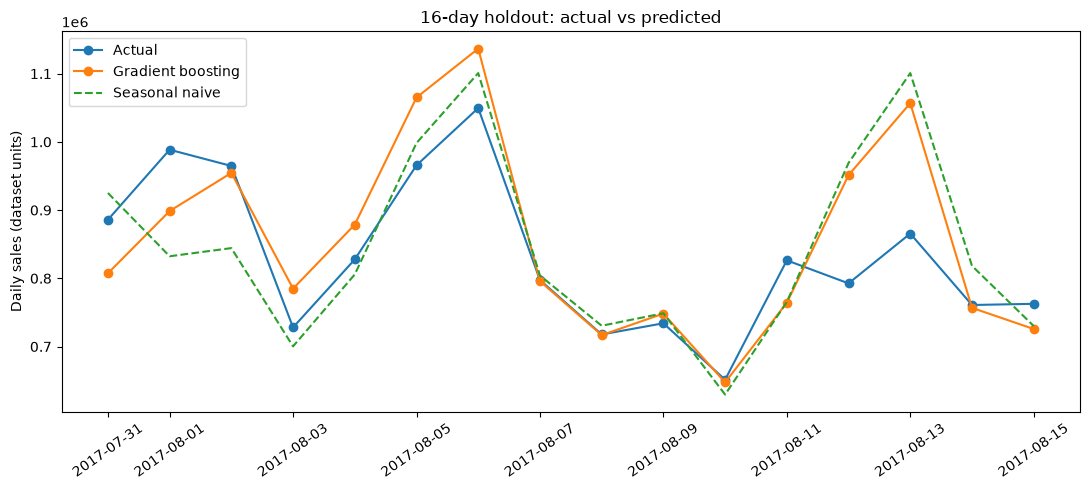

In [8]:
plt.figure(figsize=(11,5))
plt.plot(y_val.index,y_val.values,marker='o',label='Actual')
plt.plot(y_val.index,val_predictions,marker='o',label='Gradient boosting')
plt.plot(y_val.index,baseline,linestyle='--',label='Seasonal naive')
plt.xticks(rotation=35);plt.ylabel('Daily sales (dataset units)')
plt.title('16-day holdout: actual vs predicted');plt.legend();plt.tight_layout();plt.show()

**Interpretation:** lower MAE and RMSE are better. A model should be compared with a simple baseline, not judged by its error in isolation. One holdout window is illustrative, not proof of reliable performance across different seasons. In production, use rolling-origin backtesting across several 16-day windows.

## 8. Refit on observed history and forecast the Kaggle test dates

In [9]:
final_model=HistGradientBoostingRegressor(
    max_iter=250,max_leaf_nodes=15,learning_rate=0.05,
    l2_regularization=10,random_state=42)
valid_history=X.notna().all(axis=1)
final_model.fit(X.loc[valid_history],y.loc[valid_history])
X_future=Xall.loc[test_daily.index]
assert X_future.notna().all().all(), 'Missing future features'
future_forecast=np.maximum(final_model.predict(X_future),0)
forecast_df=pd.DataFrame({'date':X_future.index,'predicted_total_sales':future_forecast})
forecast_df

,date,predicted_total_sales
0,2017-08-16,7.853511e+05
1,2017-08-17,6.452535e+05
2,2017-08-18,7.779547e+05
3,2017-08-19,9.333427e+05
4,2017-08-20,1.020612e+06
5,2017-08-21,7.339538e+05
6,2017-08-22,7.328249e+05
7,2017-08-23,7.742398e+05
8,2017-08-24,6.394174e+05
9,2017-08-25,7.644141e+05


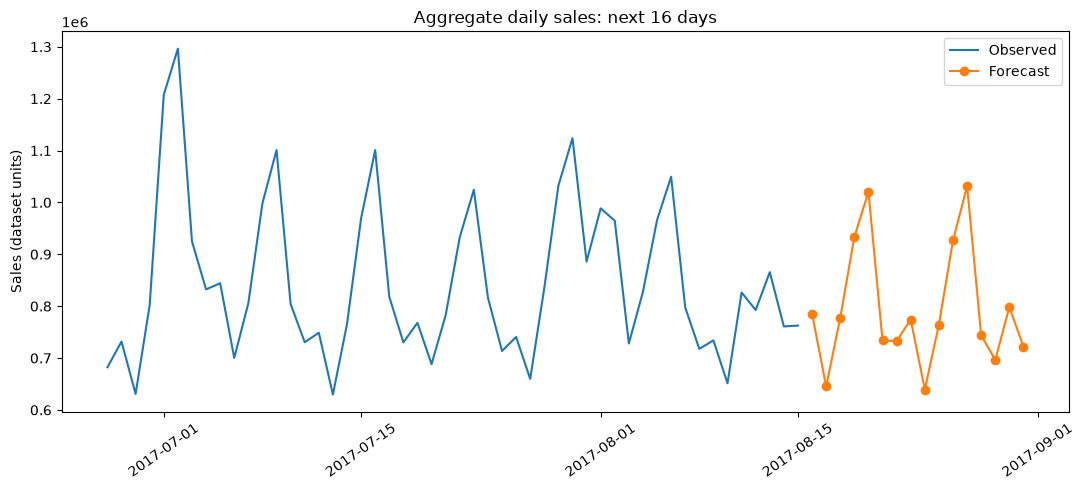

In [10]:
plt.figure(figsize=(11,5))
plt.plot(daily.tail(50).index,daily.tail(50)['sales'],label='Observed')
plt.plot(forecast_df['date'],forecast_df['predicted_total_sales'],marker='o',label='Forecast')
plt.xticks(rotation=35);plt.ylabel('Sales (dataset units)')
plt.title('Aggregate daily sales: next 16 days');plt.legend();plt.tight_layout();plt.show()

In [11]:
Path('outputs').mkdir(exist_ok=True)
forecast_df.to_csv('outputs/daily_sales_forecast.csv',index=False)
results.to_csv('outputs/validation_metrics.csv',index=False)
print('Saved forecasts and validation metrics.')

Saved forecasts and validation metrics.


## 9. Conclusion and limitations

This project illustrates a full aggregate time-series forecasting workflow: temporal aggregation, EDA, horizon-safe lag features, chronological validation, a seasonal-naive benchmark, gradient boosting, and a 16-day forward forecast.

**Limitations:** it does not forecast each store/family separately, uses one validation window, and does not include external features from oil prices or holidays. Promotional counts are assumed to be known in advance (as provided in the competition test file). Future improvements include rolling backtests, store/family models, and carefully aligned holiday features.